In [9]:
#correction, adding price-ratio as a feature and deleting product_number and log_sales_price as a feature 
# Two-part sales forecasting model (self-contained, no model saving)
# Part 1: classifier (normal vs bulk)
# Part 2: regressor on normal sales + threshold selection + evaluation
# Part 3: prediction function for any new data (same features, unknown quantity)


import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype
from lightgbm import LGBMRegressor, LGBMClassifier, early_stopping

# Settings
DATA_PATH = "famco_model2_product_feature.csv"
BULK_THRESHOLD = 50          # quantity > 50 -> bulk order (business policy)
TARGET_BULK_RECALL = 0.80    # catch at least 80% of true bulk orders (validation)

FEATURES = [
    #product_number
    "sales_Price", "price_ratio", 
    "hour_sin", "hour_cos", "dow_sin", "dow_cos", "day_of_month",
    "month_sin", "month_cos",
    "previous_quantity", "sales_count", "days_since_last_sale",
    "rolling_mean_7d", "rolling_mean_30d",
]
# First sale of a product has no history -> fill with 0
FILL_ZERO_FEATURES = ["previous_quantity", "days_since_last_sale",
                      "rolling_mean_7d", "rolling_mean_30d"]

# ======================================================================
# Load data + time-based split (train / val / test)
# ======================================================================
df = pd.read_csv(DATA_PATH, dtype={"product_number": str})
df["created_on"] = pd.to_datetime(df["created_on"])
df = df.sort_values("created_on").reset_index(drop=True)

# >>> CHANGED: the line that computed price_ratio on the WHOLE dataframe was removed
# (its median included val/test data = data leakage). It is computed after the split.

split_idx = int(len(df) * 0.80)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

val_split_idx = int(len(train_df) * 0.80)
model_train_df = train_df.iloc[:val_split_idx].copy()
val_df = train_df.iloc[val_split_idx:].copy()

# Product categories are learned from the training part only
product_cat_type = CategoricalDtype(categories=model_train_df["product_number"].unique())

# >>> CHANGED: typical (median) price per product, learned from the training part ONLY
price_median = model_train_df.groupby("product_number")["sales_Price"].median()
print(type(price_median))
print(price_median.head(10))


def prepare(frame):
    frame = frame.copy()
    for col in FILL_ZERO_FEATURES:
        frame[col] = frame[col].fillna(0)
    # >>> CHANGED: price_ratio computed here with the train medians, so it is the same
    # for train / val / test / new data. Unseen product -> 1.0 (= normal price).
    frame["price_ratio"] = (
        frame["sales_Price"] / frame["product_number"].astype(str).map(price_median)
    ).fillna(1.0)
    return frame


model_train_df = prepare(model_train_df)
val_df = prepare(val_df)
test_df = prepare(test_df)

for d in (model_train_df, val_df, test_df):
    d["is_bulk"] = (d["quantity"] > BULK_THRESHOLD).astype(int)

print(f"Bulk threshold: quantity > {BULK_THRESHOLD}")
print("\nBulk distribution:")
for name, d in [("Train", model_train_df), ("Val", val_df), ("Test", test_df)]:
    n_bulk = d["is_bulk"].sum()
    print(f"{name}: {n_bulk} bulk records out of {len(d)} ({n_bulk / len(d):.1%})")

X_train, X_val, X_test = model_train_df[FEATURES], val_df[FEATURES], test_df[FEATURES]
y_train_class, y_val_class = model_train_df["is_bulk"], val_df["is_bulk"]
y_test = test_df["quantity"]

# PART 1: Classifier (normal vs bulk)

clf = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbose=-1,
)
clf.fit(
    X_train, y_train_class,
    eval_set=[(X_val, y_val_class)],
    callbacks=[early_stopping(stopping_rounds=50, verbose=False)],
)
print(f"\nClassifier best iteration: {clf.best_iteration_}")

# PART 2: Regressor on normal sales only + bulk-probability threshold

normal_train = model_train_df[model_train_df["is_bulk"] == 0]
normal_val = val_df[val_df["is_bulk"] == 0]

# >>> CHANGED: monotone constraint. -1 = prediction can only go down (or stay equal)
# when price_ratio goes up. Other features are unconstrained.
monotone = [0] * len(FEATURES)
for f in ["price_ratio", "sales_Price"]:
    monotone[FEATURES.index(f)] = -1

reg_normal = LGBMRegressor(
    objective="tweedie",
    tweedie_variance_power=1.5,
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    monotone_constraints=monotone,                 # >>> CHANGED
    monotone_constraints_method="advanced",        # >>> CHANGED
    random_state=42,
    verbose=-1,
)
reg_normal.fit(
    normal_train[FEATURES], normal_train["quantity"],
    eval_set=[(normal_val[FEATURES], normal_val["quantity"])],
    callbacks=[early_stopping(stopping_rounds=50, verbose=False)],
)

# Choose bulk-probability threshold on validation
p_val = clf.predict_proba(X_val)[:, 1]
is_bulk_v = val_df["is_bulk"].values == 1
grid = np.round(np.arange(0.10, 0.95, 0.05), 2)
recalls = np.array([((p_val >= t) & is_bulk_v).sum() / is_bulk_v.sum() for t in grid])

meets_target = grid[recalls >= TARGET_BULK_RECALL]
if len(meets_target) > 0:
    best_t = float(meets_target.max())       # highest threshold that still meets the target
else:
    best_t = float(grid[recalls.argmax()])   # target not reachable -> most sensitive threshold
    print(f"Note: recall target {TARGET_BULK_RECALL:.0%} not reachable on validation; "
          f"using threshold {best_t}.")

# ---------- Evaluation on test ----------
p_test = clf.predict_proba(X_test)[:, 1]
y_t = y_test.values
is_bulk_t = test_df["is_bulk"].values == 1

bulk_group = p_test >= best_t
normal_group = ~bulk_group

forecast = np.maximum(reg_normal.predict(X_test), 0)   # used ONLY for the normal group
err = np.abs(y_t - forecast)

total = len(y_t)
n_normal, n_bulk = normal_group.sum(), bulk_group.sum()

print("\n" + "=" * 55)
print("NORMAL SALES  (model forecasts these)")
print("=" * 55)
print(f"Orders:                         {n_normal} ({n_normal / total:.1%} of all orders)")
print(f"Average error (MAE):            {err[normal_group].mean():.2f} units")
print(f"Typical error (median):         {np.median(err[normal_group]):.2f} units")
print(f"Forecast within 2 units:        {(err[normal_group] <= 2).mean():.1%} of orders")
print(f"Bulk orders wrongly included:   {(normal_group & is_bulk_t).sum()}")

print("\n" + "=" * 55)
print("BULK SALES - CAN'T FORECAST  (no number given)")
print("=" * 55)
print(f"Orders:                         {n_bulk} ({n_bulk / total:.1%} of all orders)")
print(f"Share of total units sold:      {y_t[bulk_group].sum() / y_t.sum():.1%}")
print(f"Real bulk orders found:         {(bulk_group & is_bulk_t).sum()} of {is_bulk_t.sum()} "
      f"({(bulk_group & is_bulk_t).sum() / is_bulk_t.sum():.1%})")
print(f"Normal orders wrongly included: {(bulk_group & ~is_bulk_t).sum()}")
print(f"\n(Bulk = quantity > {BULK_THRESHOLD}; bulk-probability threshold = {best_t})")


# PART 3: Prediction function for any new data
#uses the models trained above

def predict_orders(new_df):
    # >>> CHANGED: price_ratio is computed inside prepare(), so new data must contain
    # product_number and sales_Price (instead of price_ratio).
    required = [c for c in FEATURES if c != "price_ratio"] + ["product_number", "sales_Price"]
    missing = [c for c in dict.fromkeys(required) if c not in new_df.columns]
    if missing:
        raise ValueError(f"Missing feature columns: {missing}")

    X = prepare(new_df)[FEATURES]   # unseen product -> price_ratio = 1.0

    p_bulk = clf.predict_proba(X)[:, 1]
    is_bulk = p_bulk >= best_t
    qty = np.maximum(reg_normal.predict(X), 0)
    qty = np.where(is_bulk, np.nan, qty)

    return pd.DataFrame(
        {
            "group": np.where(is_bulk, "bulk", "normal"),
            "bulk_probability": p_bulk,
            "predicted_quantity": qty,
        },
        index=new_df.index,
    )


if __name__ == "__main__":
    # >>> CHANGED: sample must include product_number (needed to compute price_ratio)
    sample = test_df.head(5)
    print("\nExample prediction:")
    print(predict_orders(sample))

<class 'pandas.core.series.Series'>
product_number
1010102001    298909000.0
1010102033    620274000.0
1010102034    310000000.0
1010105004    217000000.0
1010105008    700000000.0
1010106002    230000000.0
1010106003    336360000.0
1010110004    172730000.0
1010113001    177272000.0
1010114001    392000000.0
Name: sales_Price, dtype: float64
Bulk threshold: quantity > 50

Bulk distribution:
Train: 461 bulk records out of 6244 (7.4%)
Val: 122 bulk records out of 1562 (7.8%)
Test: 123 bulk records out of 1952 (6.3%)

Classifier best iteration: 106

NORMAL SALES  (model forecasts these)
Orders:                         1682 (86.2% of all orders)
Average error (MAE):            9.63 units
Typical error (median):         1.12 units
Forecast within 2 units:        68.5% of orders
Bulk orders wrongly included:   23

BULK SALES - CAN'T FORECAST  (no number given)
Orders:                         270 (13.8% of all orders)
Share of total units sold:      89.6%
Real bulk orders found:         100 

In [10]:
#sensititvity analysis- with having price-ratio
#Analyze normal-sale price history, identify eligible products, and test prediction sensitivity to historical price changes.
# Changes relative to the previous version are marked with:  # >>> CHANGED

normal_df = df[df["quantity"] <= BULK_THRESHOLD].copy()

# Summarize historical sales and distinct prices per product
stats = (
    normal_df.groupby("product_number")
    .agg(
        n_orders=("sales_Price", "size"),
        n_unique_prices=("sales_Price", "nunique"),
        min_price=("sales_Price", "min"),
        max_price=("sales_Price", "max"),
    )
)

eligible = stats[stats["n_unique_prices"] >= 3].copy()

# >>> CHANGED: keep only products seen in the training part (they have a price_median),
# otherwise price_ratio is always 1.0 and the test is meaningless for them
eligible_products = eligible.index.intersection(price_median.index)
eligible = eligible.loc[eligible_products]

#the suitable data is printed-only 20 numbers of them
print(f"Products with normal sales: {len(stats):,}")
print(f"Eligible products (>= 3 distinct prices): {len(eligible):,}")
print(f"Share eligible: {len(eligible) / len(stats):.2%}")
print(f"Share with >= 2 distinct prices: {(stats['n_unique_prices'] >= 2).mean():.2%}")
print(f"Share with >= 3 distinct prices: {(stats['n_unique_prices'] >= 3).mean():.2%}")
print(f"Share with only 1 order: {(stats['n_orders'] == 1).mean():.2%}")

print("\nEligible products — descriptive statistics:")
display(eligible.describe().round(2))

print("\nFirst 20 eligible products:")
display(eligible.head(20))

# Test how predicted normal-sale quantities change across each eligible product's historical prices
results = []

for product_id in eligible_products:
    product_history = normal_df[
        normal_df["product_number"] == product_id
    ].sort_values("created_on")

    # >>> CHANGED: price_ratio does not exist in the raw df -> take the other features
    # plus product_number (prepare() needs it to compute price_ratio)
    base_cols = [c for c in FEATURES if c != "price_ratio"] + ["product_number"]
    base_row = product_history.iloc[[-1]][base_cols].copy()
    candidate_prices = sorted(product_history["sales_Price"].dropna().unique())

    for price in candidate_prices:
        candidate = base_row.copy()
        candidate["sales_Price"] = price

        # >>> CHANGED: prepare() recomputes price_ratio from the new price;
        # [FEATURES] drops product_number so columns match the model
        X_candidate = prepare(candidate)[FEATURES]
        bulk_probability = clf.predict_proba(X_candidate)[0, 1]
        predicted_quantity = max(0, float(reg_normal.predict(X_candidate)[0]))

        results.append({
            "product_number": product_id,
            "candidate_price": price,
            "bulk_probability": bulk_probability,
            "predicted_quantity": predicted_quantity,
            "predicted_as_normal": bulk_probability < best_t,
        })
                # # فقط برای اولین محصول، مرحله به مرحله نشون بده
#         if product_id == list(eligible_products)[0]:
#             print(f"--- قیمت تست‌شده: {price} ---")
#             print(f"  احتمال Bulk: {bulk_probability:.3f}")
#             print(f"  تعداد پیش‌بینی‌شده: {predicted_quantity:.2f}")
#             print(f"  آیا عادی تشخیص داده شد؟ {bulk_probability < best_t}")
#             print()
#
#             # فقط ۴ تا اول رو نشون بده
#             if len([r for r in results if r["product_number"] == product_id]) >= 4:
#                 break

         
sensitivity_df = pd.DataFrame(results)
#added
direction_check = (
    sensitivity_df.groupby("product_number")
    .apply(
        lambda g: (
            g.sort_values("candidate_price")["predicted_quantity"]
            .diff()
            .dropna() <= 1e-8
        ).all()
    )
)

print("Products with non-increasing predictions:",
      direction_check.sum(), "out of", len(direction_check))

print("Share:", f"{direction_check.mean():.2%}")

summary = (
    sensitivity_df.groupby("product_number")
    .agg(
        n_candidate_prices=("candidate_price", "nunique"),
        min_candidate_price=("candidate_price", "min"),
        max_candidate_price=("candidate_price", "max"),
        min_predicted_qty=("predicted_quantity", "min"),
        max_predicted_qty=("predicted_quantity", "max"),
        min_bulk_probability=("bulk_probability", "min"),
        max_bulk_probability=("bulk_probability", "max"),
        normal_candidates=("predicted_as_normal", "sum"),
    )
)

summary["quantity_change"] = (
    summary["max_predicted_qty"] - summary["min_predicted_qty"]
)

print("\nPrediction sensitivity summary:")
display(summary.describe().round(3))

print("\nFirst 20 products:")
display(summary.head(20))

print("\nCandidate-level predictions — first 30 rows:")
display(sensitivity_df.head(30))


Products with normal sales: 5,414
Eligible products (>= 3 distinct prices): 487
Share eligible: 9.00%
Share with >= 2 distinct prices: 22.64%
Share with >= 3 distinct prices: 9.42%
Share with only 1 order: 74.82%

Eligible products — descriptive statistics:


,n_orders,n_unique_prices,min_price,max_price
count,487.00,487.00,4.870000e+02,4.870000e+02
mean,6.25,5.20,3.214139e+08,4.927813e+08
std,11.22,7.43,1.056809e+09,1.492270e+09
min,3.00,3.00,3.000000e+04,6.000000e+04
25%,3.00,3.00,2.815000e+07,5.427273e+07
50%,4.00,4.00,8.800000e+07,1.486000e+08
75%,6.00,5.00,2.200000e+08,3.380000e+08
max,223.00,149.00,1.084409e+10,1.560000e+10



First 20 eligible products:


,n_orders,n_unique_prices,min_price,max_price
product_number,,,,
1010202041,3,3,8.585000e+08,9.242900e+08
1010204017,3,3,7.600000e+08,1.200000e+09
1010204053,4,4,2.833600e+08,3.652000e+08
1010204073,3,3,1.040000e+09,1.812300e+09
1010302004,6,5,1.350000e+08,2.290000e+08
1010506004,3,3,1.072730e+08,1.969000e+08
1010506014,3,3,6.100000e+07,8.636400e+07
1010506015,7,6,7.272800e+07,1.250000e+08
1010506022,4,3,8.290000e+07,1.627500e+08


Products with non-increasing predictions: 487 out of 487
Share: 100.00%

Prediction sensitivity summary:


,n_candidate_prices,min_candidate_price,max_candidate_price,min_predicted_qty,max_predicted_qty,min_bulk_probability,max_bulk_probability,normal_candidates,quantity_change
count,487.000,4.870000e+02,4.870000e+02,487.000,487.000,487.000,487.000,487.000,487.000
mean,5.195,3.214139e+08,4.927813e+08,3.281,4.383,0.016,0.049,5.062,1.102
std,7.428,1.056809e+09,1.492270e+09,3.347,3.893,0.085,0.143,7.443,1.369
min,3.000,3.000000e+04,6.000000e+04,1.229,1.257,0.001,0.003,0.000,0.000
25%,3.000,2.815000e+07,5.427273e+07,1.625,2.135,0.003,0.003,3.000,0.304
50%,4.000,8.800000e+07,1.486000e+08,2.127,2.826,0.003,0.007,4.000,0.729
75%,5.000,2.200000e+08,3.380000e+08,3.382,5.298,0.004,0.019,5.000,1.432
max,149.000,1.084409e+10,1.560000e+10,25.084,25.084,0.969,0.979,149.000,12.529



First 20 products:


,n_candidate_prices,min_candidate_price,max_candidate_price,min_predicted_qty,max_predicted_qty,min_bulk_probability,max_bulk_probability,normal_candidates,quantity_change
product_number,,,,,,,,,
1010202041,3,8.585000e+08,9.242900e+08,1.669655,1.762863,0.002885,0.002885,3,0.093208
1010204017,3,7.600000e+08,1.200000e+09,1.594262,2.323349,0.002897,0.002897,3,0.729087
1010204053,4,2.833600e+08,3.652000e+08,1.625138,1.809273,0.005707,0.006173,4,0.184135
1010204073,3,1.040000e+09,1.812300e+09,1.533085,2.303625,0.002892,0.002897,3,0.770540
1010302004,5,1.350000e+08,2.290000e+08,1.671066,2.036555,0.002859,0.002864,5,0.365489
1010506004,3,1.072730e+08,1.969000e+08,1.746251,2.659406,0.002897,0.113912,3,0.913155
1010506014,3,6.100000e+07,8.636400e+07,1.761108,2.413833,0.001808,0.009696,3,0.652724
1010506015,6,7.272800e+07,1.250000e+08,1.565233,1.962060,0.002409,0.003904,6,0.396827
1010506022,3,8.290000e+07,1.627500e+08,1.974031,3.052021,0.002874,0.007613,3,1.077991



Candidate-level predictions — first 30 rows:


,product_number,candidate_price,bulk_probability,predicted_quantity,predicted_as_normal
0,1010202041,8.585000e+08,0.002885,1.762863,True
1,1010202041,8.780750e+08,0.002885,1.762863,True
2,1010202041,9.242900e+08,0.002885,1.669655,True
3,1010204017,7.600000e+08,0.002897,2.323349,True
4,1010204017,7.900000e+08,0.002897,2.323349,True
5,1010204017,1.200000e+09,0.002897,1.594262,True
6,1010204053,2.833600e+08,0.005707,1.809273,True
7,1010204053,3.080000e+08,0.005707,1.767332,True
8,1010204053,3.510000e+08,0.006173,1.632452,True
9,1010204053,3.652000e+08,0.006173,1.625138,True


In [15]:
#sensitivity analysis with dataset+ out of dataset price range
#sensititvity analysis- correction with having price-ratio
#Analyze normal-sale price history, identify eligible products, and test prediction sensitivity to historical price changes.

# merging dataset with out of dataset
# How far outside the observed [min, max] price range candidates are allowed (10% each side)
LOWER_EXTEND = 0.90
UPPER_EXTEND = 1.10
N_GRID = 30   # number of grid points over the extended range

normal_df = df[df["quantity"] <= BULK_THRESHOLD].copy()

# Summarize historical sales and distinct prices per product
stats = (
    normal_df.groupby("product_number")
    .agg(
        n_orders=("sales_Price", "size"),
        n_unique_prices=("sales_Price", "nunique"),
        min_price=("sales_Price", "min"),
        max_price=("sales_Price", "max"),
    )
)

eligible = stats[stats["n_unique_prices"] >= 3].copy()

# keep only products seen in the training part (they have a price_median),
# otherwise price_ratio is always 1.0 and the test is meaningless for them
eligible_products = eligible.index.intersection(price_median.index)
eligible = eligible.loc[eligible_products]

#the suitable data is printed-only 20 numbers of them
print(f"Products with normal sales: {len(stats):,}")
print(f"Eligible products (>= 3 distinct prices): {len(eligible):,}")
print(f"Share eligible: {len(eligible) / len(stats):.2%}")
print(f"Share with >= 2 distinct prices: {(stats['n_unique_prices'] >= 2).mean():.2%}")
print(f"Share with >= 3 distinct prices: {(stats['n_unique_prices'] >= 3).mean():.2%}")
print(f"Share with only 1 order: {(stats['n_orders'] == 1).mean():.2%}")

print("\nEligible products — descriptive statistics:")
display(eligible.describe().round(2))

print("\nFirst 20 eligible products:")
display(eligible.head(20))

# Test how predicted normal-sale quantities change across candidate prices
results = []

for product_id in eligible_products:
    product_history = normal_df[
        normal_df["product_number"] == product_id
    ].sort_values("created_on")

    # price_ratio does not exist in the raw df -> take the other features
    # plus product_number (prepare() needs it to compute price_ratio)
    base_cols = [c for c in FEATURES if c != "price_ratio"] + ["product_number"]
    base_row = product_history.iloc[[-1]][base_cols].copy()

    # merging dataset with out of dataset
    # Candidates = observed prices + a grid over [min*0.90, max*1.10] (goes slightly outside history)
    hist_prices = product_history["sales_Price"].dropna()
    hist_min, hist_max = hist_prices.min(), hist_prices.max()
    candidate_prices = np.unique(np.concatenate([
        hist_prices.unique(),
        np.linspace(hist_min * LOWER_EXTEND, hist_max * UPPER_EXTEND, N_GRID),
    ]))

    for price in candidate_prices:
        candidate = base_row.copy()
        candidate["sales_Price"] = price

        # prepare() recomputes price_ratio from the new price;
        # [FEATURES] drops product_number so columns match the model
        X_candidate = prepare(candidate)[FEATURES]
        bulk_probability = clf.predict_proba(X_candidate)[0, 1]
        predicted_quantity = max(0, float(reg_normal.predict(X_candidate)[0]))

        results.append({
            "product_number": product_id,
            "candidate_price": price,
            "bulk_probability": bulk_probability,
            "predicted_quantity": predicted_quantity,
            "predicted_as_normal": bulk_probability < best_t,
            # merging dataset with out of dataset
            # True = inside observed range (model-backed), False = extrapolated (model is flat here)
            "inside_hist_range": bool(hist_min <= price <= hist_max),
        })
#           # فقط برای اولین محصول، مرحله به مرحله نشون بده
#         if product_id == list(eligible_products)[0]:
#             print(f"--- قیمت تست‌شده: {price} ---")
#             print(f"  احتمال Bulk: {bulk_probability:.3f}")
#             print(f"  تعداد پیش‌بینی‌شده: {predicted_quantity:.2f}")
#             print(f"  آیا عادی تشخیص داده شد؟ {bulk_probability < best_t}")
#             print()

#             # فقط ۴ تا اول رو نشون بده
#             if len([r for r in results if r["product_number"] == product_id]) >= 4:
#                 break


sensitivity_df = pd.DataFrame(results)

#added
direction_check = (
    sensitivity_df.groupby("product_number")
    .apply(
        lambda g: (
            g.sort_values("candidate_price")["predicted_quantity"]
            .diff()
            .dropna() <= 1e-8
        ).all()
    )
)

print("Products with non-increasing predictions:",
      direction_check.sum(), "out of", len(direction_check))

print("Share:", f"{direction_check.mean():.2%}")

summary = (
    sensitivity_df.groupby("product_number")
    .agg(
        n_candidate_prices=("candidate_price", "nunique"),
        min_candidate_price=("candidate_price", "min"),
        max_candidate_price=("candidate_price", "max"),
        min_predicted_qty=("predicted_quantity", "min"),
        max_predicted_qty=("predicted_quantity", "max"),
        min_bulk_probability=("bulk_probability", "min"),
        max_bulk_probability=("bulk_probability", "max"),
        normal_candidates=("predicted_as_normal", "sum"),
    )
)

summary["quantity_change"] = (
    summary["max_predicted_qty"] - summary["min_predicted_qty"]
)

print("\nPrediction sensitivity summary:")
display(summary.describe().round(3))

print("\nFirst 20 products:")
display(summary.head(20))

print("\nCandidate-level predictions — first 30 rows:")
display(sensitivity_df.head(30))

Products with normal sales: 5,414
Eligible products (>= 3 distinct prices): 487
Share eligible: 9.00%
Share with >= 2 distinct prices: 22.64%
Share with >= 3 distinct prices: 9.42%
Share with only 1 order: 74.82%

Eligible products — descriptive statistics:


,n_orders,n_unique_prices,min_price,max_price
count,487.00,487.00,4.870000e+02,4.870000e+02
mean,6.25,5.20,3.214139e+08,4.927813e+08
std,11.22,7.43,1.056809e+09,1.492270e+09
min,3.00,3.00,3.000000e+04,6.000000e+04
25%,3.00,3.00,2.815000e+07,5.427273e+07
50%,4.00,4.00,8.800000e+07,1.486000e+08
75%,6.00,5.00,2.200000e+08,3.380000e+08
max,223.00,149.00,1.084409e+10,1.560000e+10



First 20 eligible products:


,n_orders,n_unique_prices,min_price,max_price
product_number,,,,
1010202041,3,3,8.585000e+08,9.242900e+08
1010204017,3,3,7.600000e+08,1.200000e+09
1010204053,4,4,2.833600e+08,3.652000e+08
1010204073,3,3,1.040000e+09,1.812300e+09
1010302004,6,5,1.350000e+08,2.290000e+08
1010506004,3,3,1.072730e+08,1.969000e+08
1010506014,3,3,6.100000e+07,8.636400e+07
1010506015,7,6,7.272800e+07,1.250000e+08
1010506022,4,3,8.290000e+07,1.627500e+08


Products with non-increasing predictions: 487 out of 487
Share: 100.00%

Prediction sensitivity summary:


,n_candidate_prices,min_candidate_price,max_candidate_price,min_predicted_qty,max_predicted_qty,min_bulk_probability,max_bulk_probability,normal_candidates,quantity_change
count,487.000,4.870000e+02,4.870000e+02,487.000,487.000,487.000,487.000,487.000,487.000
mean,35.195,2.892725e+08,5.420595e+08,3.165,4.542,0.013,0.060,34.460,1.377
std,7.428,9.511285e+08,1.641497e+09,3.310,3.954,0.079,0.154,8.463,1.493
min,33.000,2.700000e+04,6.600000e+04,1.229,1.295,0.001,0.003,0.000,0.000
25%,33.000,2.533500e+07,5.970000e+07,1.581,2.224,0.003,0.004,33.000,0.430
50%,34.000,7.920000e+07,1.634600e+08,1.965,2.954,0.003,0.011,34.000,0.906
75%,35.000,1.980000e+08,3.718000e+08,3.227,5.433,0.004,0.033,35.000,1.844
max,179.000,9.759682e+09,1.716000e+10,25.084,25.084,0.969,0.979,179.000,12.688



First 20 products:


,n_candidate_prices,min_candidate_price,max_candidate_price,min_predicted_qty,max_predicted_qty,min_bulk_probability,max_bulk_probability,normal_candidates,quantity_change
product_number,,,,,,,,,
1010202041,33,772650000.0,1.016719e+09,1.488010,1.762863,0.002880,0.002885,33,0.274853
1010204017,33,684000000.0,1.320000e+09,1.594262,2.380173,0.002892,0.002897,33,0.785911
1010204053,34,255024000.0,4.017200e+08,1.402486,1.809273,0.005707,0.006173,34,0.406786
1010204073,33,936000000.0,1.993530e+09,1.533085,2.370932,0.002892,0.002897,33,0.837847
1010302004,35,121500000.0,2.519000e+08,1.671066,2.036555,0.002859,0.018309,35,0.365489
1010506004,33,96545700.0,2.165900e+08,1.746251,2.758009,0.002897,0.113912,33,1.011758
1010506014,33,54900000.0,9.500040e+07,1.761108,2.413833,0.001808,0.009696,33,0.652724
1010506015,36,65455200.0,1.375000e+08,1.565233,2.135228,0.002366,0.004511,36,0.569995
1010506022,33,74610000.0,1.790250e+08,1.974031,3.476954,0.001950,0.014712,33,1.502923



Candidate-level predictions — first 30 rows:


,product_number,candidate_price,bulk_probability,predicted_quantity,predicted_as_normal,inside_hist_range
0,1010202041,7.726500e+08,0.002880,1.762863,True,False
1,1010202041,7.810662e+08,0.002880,1.762863,True,False
2,1010202041,7.894823e+08,0.002880,1.762863,True,False
3,1010202041,7.978985e+08,0.002880,1.762863,True,False
4,1010202041,8.063147e+08,0.002880,1.762863,True,False
5,1010202041,8.147309e+08,0.002880,1.762863,True,False
6,1010202041,8.231470e+08,0.002880,1.762863,True,False
7,1010202041,8.315632e+08,0.002880,1.762863,True,False
8,1010202041,8.399794e+08,0.002885,1.762863,True,False
9,1010202041,8.483956e+08,0.002885,1.762863,True,False


In [11]:
# optimization-correction, adding some changes in print commands
# PART 5: exhaustive search for the profit-maximizing price per eligible product
# Runs after Part 4 (uses normal_df and sensitivity_df: candidate prices, predicted quantity, normal/bulk flag)
# Current cost = latest purchase_Price of each product
latest_cost = (
    normal_df.sort_values("created_on")
    .groupby("product_number")["purchase_Price"]
    .last()
    .rename("purchase_price")
)
exhaustive_df = sensitivity_df.merge(latest_cost, on="product_number", how="left")

# Constraints: strictly positive margin, and the forecast is only valid for normal (non-bulk) sales
exhaustive_df = exhaustive_df[
    (exhaustive_df["candidate_price"] > exhaustive_df["purchase_price"])
    & exhaustive_df["predicted_as_normal"]
].copy()

# Objective: profit per order = (price - cost) * predicted quantity
exhaustive_df["margin"] = exhaustive_df["candidate_price"] - exhaustive_df["purchase_price"]
exhaustive_df["expected_profit"] = exhaustive_df["margin"] * exhaustive_df["predicted_quantity"]

# Best price per product (independent products -> separate search for each)
best_idx = exhaustive_df.groupby("product_number")["expected_profit"].idxmax()
optimal = (
    exhaustive_df.loc[best_idx]
    .rename(columns={"candidate_price": "optimal_price"})
    .set_index("product_number")
)
optimal["last_price"] = normal_df.sort_values("created_on").groupby("product_number")["sales_Price"].last()
optimal["max_valid_price"] = exhaustive_df.groupby("product_number")["candidate_price"].max()
optimal["min_valid_price"] = exhaustive_df.groupby("product_number")["candidate_price"].min()
optimal["n_valid_prices"] = exhaustive_df.groupby("product_number")["candidate_price"].nunique()

# Sanity flags
optimal["at_max_price"] = optimal["optimal_price"] == optimal["max_valid_price"]
optimal["at_min_price"] = optimal["optimal_price"] == optimal["min_valid_price"]
optimal = optimal[["purchase_price", "last_price", "optimal_price", "predicted_quantity", "margin",
                   "expected_profit", "bulk_probability", "n_valid_prices",
                   "at_max_price", "at_min_price"]]

# Only products with >= 2 valid prices have a real choice -> use these for decisions
optimal_multi = optimal[optimal["n_valid_prices"] >= 2].copy()

optimal.to_csv("optimal_prices.csv")
optimal_multi.to_csv("optimal_prices_multi.csv")
exhaustive_df.to_csv("exhaustive_profit_curves.csv", index=False)

print("Products optimized (all):", len(optimal), "of", len(eligible_products))
print("Products with >= 2 valid prices:", len(optimal_multi), "of", len(optimal))
print("\nAmong products with >= 2 valid prices:")
print("  At MAX price:", optimal_multi["at_max_price"].mean())
print("  At MIN price:", optimal_multi["at_min_price"].mean())
print("\nChange vs last price (multi only):")
print("  Optimal == last price:", (optimal_multi["optimal_price"] == optimal_multi["last_price"]).mean())
print("  Optimal > last price: ", (optimal_multi["optimal_price"] > optimal_multi["last_price"]).mean())
print("  Optimal < last price: ", (optimal_multi["optimal_price"] < optimal_multi["last_price"]).mean())
print(optimal_multi.head(20))

Products optimized (all): 450 of 487
Products with >= 2 valid prices: 264 of 450

Among products with >= 2 valid prices:
  At MAX price: 0.9848484848484849
  At MIN price: 0.0

Change vs last price (multi only):
  Optimal == last price: 0.44696969696969696
  Optimal > last price:  0.5492424242424242
  Optimal < last price:  0.003787878787878788
                purchase_price    last_price  optimal_price  \
product_number                                                
1010204053        3.320000e+08  3.510000e+08   3.652000e+08   
1010519001        7.700000e+07  8.818100e+07   8.818100e+07   
1010519002        8.820000e+07  1.000000e+08   1.000000e+08   
1010605006        2.180000e+08  2.400000e+08   2.520000e+08   
1010705001        2.280000e+08  2.410000e+08   2.508000e+08   
1010705002        2.710000e+08  2.854550e+08   2.981000e+08   
1010705003        3.300000e+08  3.463630e+08   3.572730e+08   
1010707003        4.091000e+08  4.545460e+08   5.060000e+08   
1010707004        3.381

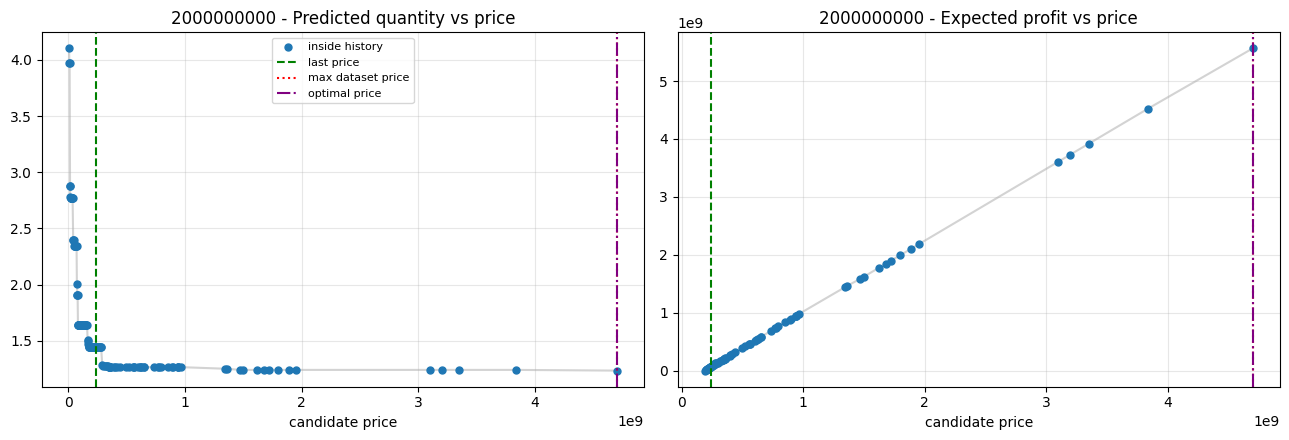

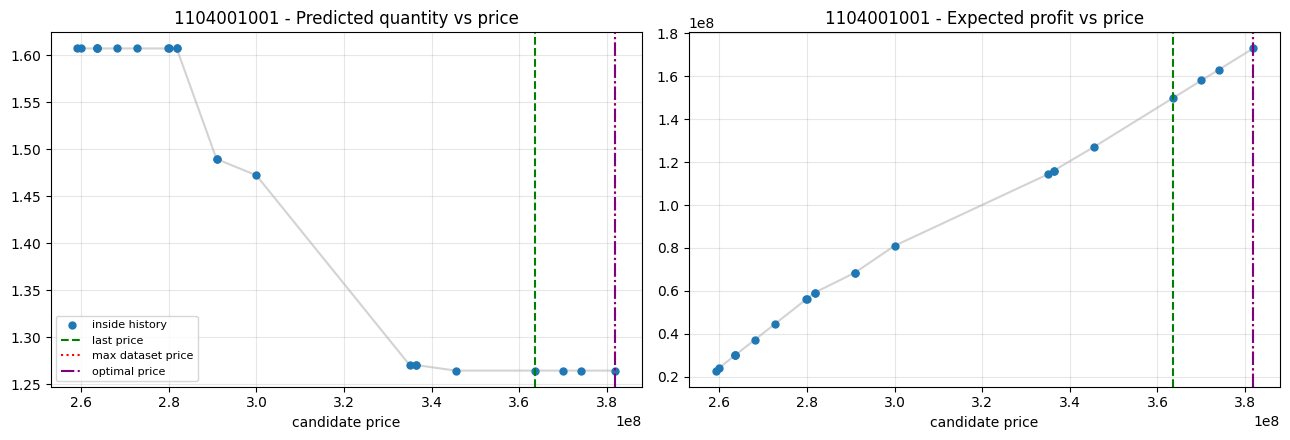

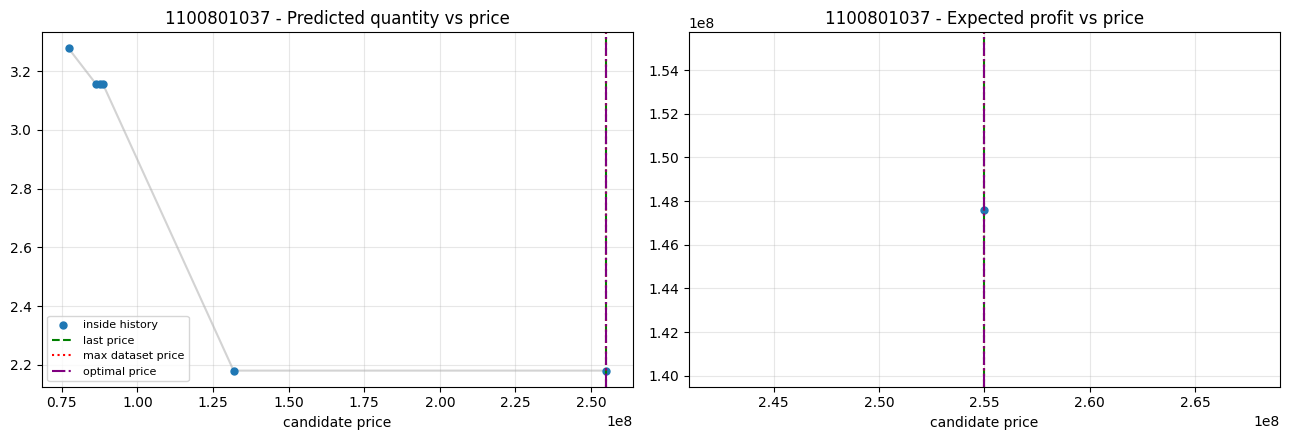

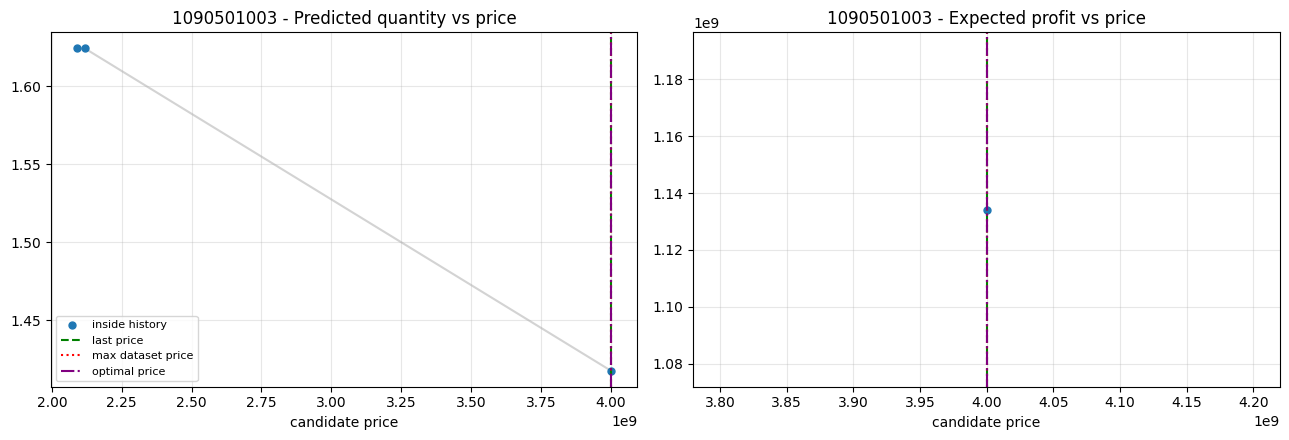

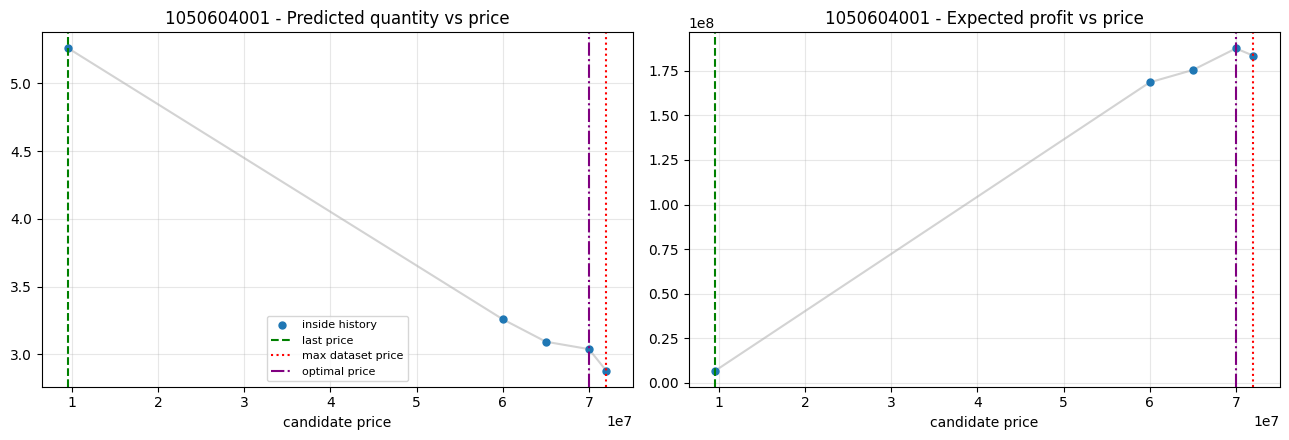

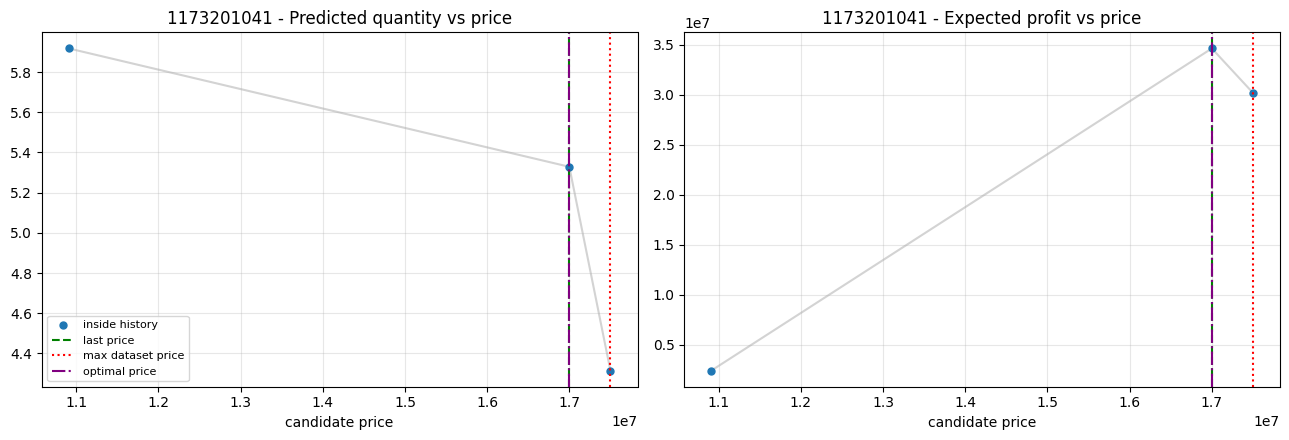

In [12]:
# Plots: predicted_quantity vs price and expected_profit vs price for selected products
# Run AFTER Part 5. Works for both modes (combined / dataset-only).
import matplotlib.pyplot as plt

curves = sensitivity_df.merge(latest_cost, on="product_number", how="left")
curves["margin"] = curves["candidate_price"] - curves["purchase_price"]
curves["profit"] = curves["margin"] * curves["predicted_quantity"]
curves.loc[curves["margin"] <= 0, "profit"] = np.nan   # same constraint as Part 5

has_inside = "inside_hist_range" in curves.columns
last_price = normal_df.sort_values("created_on").groupby("product_number")["sales_Price"].last()
hist_max = normal_df.groupby("product_number")["sales_Price"].max()

# --- choose products (edit this list by hand if you want specific ones) ---
by_n = optimal.sort_values("n_valid_prices", ascending=False)
picked = list(by_n.head(2).index)                                   # most prices
picked += list(by_n.tail(2).index)                                  # fewest prices
picked += list(optimal[~optimal["at_max_price"]].head(2).index)     # interior optimum
products_to_plot = list(dict.fromkeys(picked))
# products_to_plot = ["1010707003", "1010204053"]                   # manual override

for pid in products_to_plot:
    g = curves[curves["product_number"] == pid].sort_values("candidate_price")
    if g.empty:
        continue
    normal_pts = g[g["predicted_as_normal"]]
    bulk_pts = g[~g["predicted_as_normal"]]
    if has_inside:
        inside = normal_pts[normal_pts["inside_hist_range"]]
        outside = normal_pts[~normal_pts["inside_hist_range"]]
    else:
        inside, outside = normal_pts, normal_pts.iloc[0:0]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, col, title in [(axes[0], "predicted_quantity", "Predicted quantity vs price"),
                           (axes[1], "profit", "Expected profit vs price")]:
        ax.plot(g["candidate_price"], g[col], color="lightgray", zorder=1)
        ax.scatter(inside["candidate_price"], inside[col], s=25, color="tab:blue", label="inside history", zorder=2)
        if len(outside):
            ax.scatter(outside["candidate_price"], outside[col], s=25, color="tab:orange", label="outside history (extrapolated)", zorder=2)
        if len(bulk_pts):
            ax.scatter(bulk_pts["candidate_price"], bulk_pts[col], s=35, color="gray", marker="x", label="flagged bulk", zorder=2)
        ax.axvline(last_price[pid], color="green", ls="--", label="last price")
        ax.axvline(hist_max[pid], color="red", ls=":", label="max dataset price")
        if pid in optimal.index:
            ax.axvline(optimal.loc[pid, "optimal_price"], color="purple", ls="-.", label="optimal price")
        ax.set_title(f"{pid} - {title}")
        ax.set_xlabel("candidate price")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

Products compared: 252 of 264 (current price must also pass the cost/normal filters)
Total expected profit - current prices: 26,696,643,786
Total expected profit - optimal prices: 46,212,935,250
Uplift: 73.1%


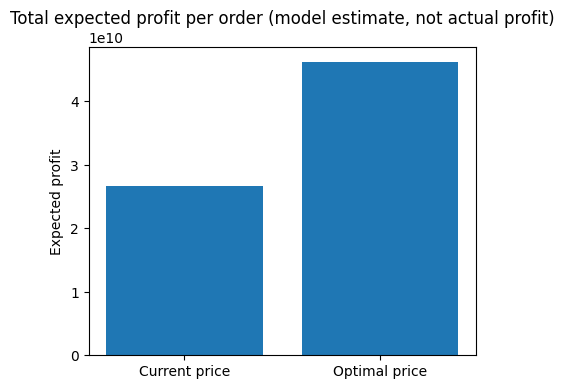


Price change (%) - summary:
count     264.00
mean       87.97
std       659.87
min        -3.81
25%         0.00
50%         1.05
75%        11.61
max      9900.00
dtype: float64
Increase: 54.9% | Same: 44.7% | Decrease: 0.4%


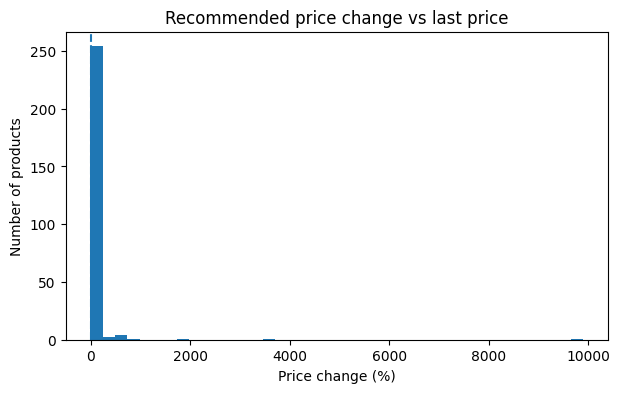

Top 10% of products -> 89.3% of total gain
Top 20% of products -> 95.2% of total gain
Top 50% of products -> 100.0% of total gain


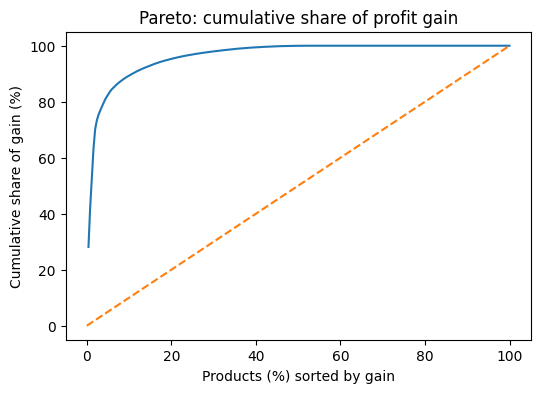

,orders,MAE,median_error,within_2_units
method,,,,
LightGBM model,968,13.80,1.08,66.6%
Naive: previous order,968,13.61,1.00,72.3%


In [14]:
#just dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 1) Expected profit: current price vs optimal price (MODEL ESTIMATE)
# =====================================================================
# Profit at the current (last) price comes from the same profit curves.
cur = exhaustive_df.merge(optimal_multi[["last_price"]],
                          left_on="product_number", right_index=True)
cur = (cur[cur["candidate_price"] == cur["last_price"]]
       .set_index("product_number")["expected_profit"]
       .rename("profit_current"))

cmp = (optimal_multi[["last_price", "optimal_price", "expected_profit"]]
       .rename(columns={"expected_profit": "profit_optimal"})
       .join(cur, how="inner"))
cmp["gain"] = cmp["profit_optimal"] - cmp["profit_current"]

tot_cur, tot_opt = cmp["profit_current"].sum(), cmp["profit_optimal"].sum()
print(f"Products compared: {len(cmp)} of {len(optimal_multi)} "
      f"(current price must also pass the cost/normal filters)")
print(f"Total expected profit - current prices: {tot_cur:,.0f}")
print(f"Total expected profit - optimal prices: {tot_opt:,.0f}")
print(f"Uplift: {tot_opt / tot_cur - 1:.1%}")

plt.figure(figsize=(5, 4))
plt.bar(["Current price", "Optimal price"], [tot_cur, tot_opt])
plt.title("Total expected profit per order (model estimate, not actual profit)")
plt.ylabel("Expected profit")
plt.show()

# =====================================================================
# 2) Distribution of recommended price change
# =====================================================================
pct = (optimal_multi["optimal_price"] / optimal_multi["last_price"] - 1) * 100

print("\nPrice change (%) - summary:")
print(pct.describe().round(2))
print(f"Increase: {(pct > 0).mean():.1%} | Same: {(pct == 0).mean():.1%} | "
      f"Decrease: {(pct < 0).mean():.1%}")

plt.figure(figsize=(7, 4))
plt.hist(pct, bins=40)
plt.axvline(0, linestyle="--")
plt.title("Recommended price change vs last price")
plt.xlabel("Price change (%)")
plt.ylabel("Number of products")
plt.show()

# =====================================================================
# 3) Pareto: where does the profit gain come from?
# =====================================================================
g = cmp["gain"].sort_values(ascending=False).reset_index(drop=True)
cum_share = g.cumsum() / g.sum() * 100
x = (np.arange(1, len(g) + 1) / len(g)) * 100

for p in (10, 20, 50):
    k = max(1, int(round(len(g) * p / 100)))
    print(f"Top {p}% of products -> {cum_share.iloc[k - 1]:.1f}% of total gain")

plt.figure(figsize=(6, 4))
plt.plot(x, cum_share)
plt.plot([0, 100], [0, 100], linestyle="--")
plt.title("Pareto: cumulative share of profit gain")
plt.xlabel("Products (%) sorted by gain")
plt.ylabel("Cumulative share of gain (%)")
plt.show()

# =====================================================================
# 4) Model accuracy on test vs naive "same as previous order"
# =====================================================================
# Uses variables from the main code: forecast, normal_group, y_t, test_df, df.
# First sale of a product has no history (previous_quantity was filled with 0
# in prepare()), so it is excluded for a fair comparison.
has_hist = df.loc[test_df.index, "previous_quantity"].notna().values
mask = normal_group & has_hist

naive = test_df["previous_quantity"].values
rows = []
for name, pred in [("LightGBM model", forecast), ("Naive: previous order", naive)]:
    e = np.abs(y_t[mask] - pred[mask])
    rows.append({"method": name,
                 "orders": int(mask.sum()),
                 "MAE": e.mean(),
                 "median_error": np.median(e),
                 "within_2_units": (e <= 2).mean()})

acc = pd.DataFrame(rows).set_index("method")
acc["within_2_units"] = (acc["within_2_units"] * 100).round(1).astype(str) + "%"
display(acc.round(2))

In [ ]:
#dataset + out of dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# Inputs rebuilt from existing variables (sensitivity_df must contain
# the column inside_hist_range)
# ---------------------------------------------------------------------
sorted_normal = normal_df.sort_values("created_on").groupby("product_number")
last_price = sorted_normal["sales_Price"].last().rename("last_price")
last_cost = sorted_normal["purchase_Price"].last()
n_orders = stats["n_orders"].rename("n_orders")

valid = sensitivity_df.copy()
valid["purchase_price"] = valid["product_number"].map(last_cost)
valid = valid[(valid["candidate_price"] > valid["purchase_price"])
              & valid["predicted_as_normal"]].copy()
valid["expected_profit"] = (valid["candidate_price"] - valid["purchase_price"]) * valid["predicted_quantity"]

def best_per_product(d):
    idx = d.groupby("product_number")["expected_profit"].idxmax()
    return d.loc[idx].set_index("product_number")

opt_all = best_per_product(valid)                              # full range (incl. extrapolated)
opt_in = best_per_product(valid[valid["inside_hist_range"]])   # observed range only

# Expected profit at the CURRENT (last) price
valid["last_price"] = valid["product_number"].map(last_price)
cur = valid[np.isclose(valid["candidate_price"], valid["last_price"])]
profit_current = cur.groupby("product_number")["expected_profit"].max().rename("profit_current")

# One table; only products that have a current price + both optima (comparable sets)
res = pd.concat([
    last_price,
    n_orders,
    profit_current,
    opt_all[["candidate_price", "expected_profit", "inside_hist_range"]]
        .rename(columns={"candidate_price": "price_all", "expected_profit": "profit_all",
                         "inside_hist_range": "all_is_inside"}),
    opt_in[["candidate_price", "expected_profit"]]
        .rename(columns={"candidate_price": "price_in", "expected_profit": "profit_in"}),
], axis=1, join="inner")

res["chg_all"] = (res["price_all"] / res["last_price"] - 1) * 100
res["chg_in"] = (res["price_in"] / res["last_price"] - 1) * 100
res["gain_all"] = res["profit_all"] - res["profit_current"]
res["gain_in"] = res["profit_in"] - res["profit_current"]

print(f"Products compared: {len(res):,} of {len(eligible_products):,} eligible "
      f"(current price must pass the cost / normal-sale filters)")

# ---------------------------------------------------------------------
# 1) Share of optima inside the observed price range
# ---------------------------------------------------------------------
print(f"\nShare of unrestricted optima inside observed range: {res['all_is_inside'].mean():.1%}")
print(f"Share outside (extrapolated):                        {(~res['all_is_inside']).mean():.1%}")

# ---------------------------------------------------------------------
# 2) Price change: shares + median + histograms
# ---------------------------------------------------------------------
def change_summary(pct, label):
    same = np.isclose(pct, 0)
    print(f"\n{label}")
    print(f"  Increase: {(pct > 0).__and__(~same).mean():.1%} | "
          f"Same: {same.mean():.1%} | Decrease: {(pct < 0).__and__(~same).mean():.1%}")
    print(f"  Median change: {pct.median():.2f}%")

change_summary(res["chg_all"], "Price change - unrestricted optimum (may be extrapolated)")
change_summary(res["chg_in"], "Price change - optimum inside observed range")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in [(axes[0], "chg_all", "Unrestricted optimum"),
                       (axes[1], "chg_in", "Inside observed range")]:
    ax.hist(res[col], bins=40)
    ax.axvline(0, linestyle="--")
    ax.set_title(f"Recommended price change vs last price\n({title})")
    ax.set_xlabel("Price change (%)")
axes[0].set_ylabel("Number of products")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# 3) Expected profit improvement (MODEL ESTIMATE, not actual profit)
# ---------------------------------------------------------------------
def gain_summary(gain, label):
    w = res["n_orders"]
    total_gain = (gain * w).sum()
    base = (res["profit_current"] * w).sum()
    print(f"\n{label}")
    print(f"  Median gain per order (per product): {gain.median():.2f}")
    print(f"  Order-weighted total expected gain:  {total_gain:,.0f}")
    print(f"  Order-weighted uplift vs current:    {total_gain / base:.1%}")

gain_summary(res["gain_all"], "Profit improvement - unrestricted optimum")
gain_summary(res["gain_in"], "Profit improvement - inside observed range (conservative estimate)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in [(axes[0], "gain_all", "Unrestricted optimum"),
                       (axes[1], "gain_in", "Inside observed range")]:
    ax.hist(res[col], bins=40)
    ax.set_title(f"Expected profit gain per order\n({title})")
    ax.set_xlabel("Gain (model estimate)")
axes[0].set_ylabel("Number of products")
plt.tight_layout()
plt.show()